# Topic 0 — Foundations of Option Pricing

*FINM 32000 Numerical Methods — Prerequisite Study Notes*

---

**Read this notebook before Topic A and all later topics.**

This notebook explains *from scratch* the ideas every formula in this course depends on. If a later notebook says "see Topic 0 §7", it means: come back here for the full derivation.

**How to use this notebook**
1. Read each section in order — later sections build on earlier ones.
2. When you see a formula, read the paragraph *before* it first. That paragraph explains *why* we need the formula.
3. Run the code cells. They check the algebra with small numbers.
4. At the end, do the Practice-Midterm walkthrough on paper before looking at the solution.

**What you should already know (we will not re-teach this)**
- A call option gives you the right (not the obligation) to buy a stock at a fixed price.
- A put option gives you the right to sell a stock at a fixed price.
- Basic probability: expected value, variance, normal distribution.

**What this notebook will teach you**
- How to price an option without guessing
- Where the risk-neutral pricing formula comes from (not magic)
- Brownian motion and Geometric Brownian Motion (GBM)
- The Black-Scholes formula, derived step by step
- What delta, gamma, and vega mean in plain English
- Forward prices and put-call parity
- Conditional expectation (the "tower property") and why it is useful


In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
%matplotlib inline
np.set_printoptions(precision=6, suppress=True)


---

# Part I — The pricing principle from scratch

## 1. What we are pricing

### The basic objects

| Term | Meaning |
|---|---|
| **Underlying** ($S$) | The stock (or index) whose price we care about |
| **Strike** ($K$) | The fixed price at which the option lets you buy or sell |
| **Expiry** ($T$) | The date when the option expires |
| **Time-$t$ price** ($S_t$) | The stock price at time $t$; at time 0 we write $S_0$ |
| **Interest rate** ($r$) | The continuously compounded risk-free rate (money in the bank grows at rate $r$) |

### Payoff functions (what you receive at expiry)

These are the *only* thing that defines a European option. Everything else (Black-Scholes, trees, Monte Carlo) is machinery to compute the **time-0 price** of that payoff.

**Call option:** right to buy at strike $K$.
$$
\text{Payoff at expiry} = (S_T - K)^+ = \max(S_T - K,\, 0).
$$
- If $S_T > K$: you buy at $K$, worth $S_T - K$.
- If $S_T \le K$: the option is worthless; you would not exercise.

**Put option:** right to sell at strike $K$.
$$
\text{Payoff at expiry} = (K - S_T)^+ = \max(K - S_T,\, 0).
$$

**Forward contract:** obligation to buy at delivery price $K$ (no optionality).
$$
\text{Payoff at expiry} = S_T - K.
$$
Can be negative — you must buy even if the stock fell.

**Digital (binary) call:** pays \$1 if $S_T > K$, else \$0.
$$
\text{Payoff at expiry} = \mathbf 1_{\{S_T > K\}}.
$$

### A concrete example (call, strike $K = 100$)

| Stock price at expiry $S_T$ | Call payoff $(S_T - 100)^+$ |
|---|---|
| 95 | 0 (not worth exercising) |
| 100 | 0 (exactly at the strike) |
| 110 | 10 (buy at 100, stock worth 110) |

**Key point:** The payoff is known. The *hard question* is: **what is this payoff worth today, at time 0?** That is what we mean by "pricing an option."


In [2]:
K = 100
for S_T in [95, 100, 110]:
    payoff = max(S_T - K, 0)
    print(f"S_T = {S_T:3d}  ->  call payoff = {payoff}")


S_T =  95  ->  call payoff = 0
S_T = 100  ->  call payoff = 0
S_T = 110  ->  call payoff = 10


## 2. The two pricing principles

Every price in this course comes from one of two ideas.

### Principle 1: No-arbitrage

> **If two portfolios have the same payoff in every possible future state, they must have the same price today.**

Why? If Portfolio A costs less than Portfolio B but pays the same, you buy A and sell B and pocket the difference for free. That is an **arbitrage** — risk-free profit with zero initial investment. In real markets, arbitrage opportunities disappear quickly. We assume they do not exist.

### Principle 2: Replication

> **If you can build a portfolio of traded assets (stock + bank account) that exactly reproduces the option's payoff at expiry, then the option's price today must equal the cost of building that portfolio today.**

This is the practical version of no-arbitrage. We do not need to guess what the option "should" cost — we **construct** a portfolio that matches the payoff and read off its cost.

### Worked example: one-period binomial tree

This is the simplest possible model. Time 0 → time $T$. Stock starts at $S_0 = 100$. At expiry, either:
- **Up state:** $S_T = S_u = 120$ (probability not yet specified)
- **Down state:** $S_T = S_d = 80$

Interest rate $r = 0$ (no growth in the bank account, to keep arithmetic simple).

**Question:** What is the time-0 price of a call with strike $K = 100$?

**Step 1 — Payoffs at expiry**
- Up: $(120 - 100)^+ = 20$
- Down: $(80 - 100)^+ = 0$

**Step 2 — Find the replicating portfolio**

We want to hold $\Delta$ shares of stock and $B$ dollars in the bank so that:
$$
\Delta \cdot 120 + B = 20 \quad \text{(up state)}
$$
$$
\Delta \cdot 80 + B = 0 \quad \text{(down state)}
$$

Subtract the second equation from the first: $\Delta \cdot 40 = 20$, so $\Delta = 0.5$ shares.
Plug back: $0.5 \cdot 80 + B = 0$, so $B = -40$ (we borrow \$40).

**Step 3 — Read off the price**

The replicating portfolio costs today:
$$
C_0 = \Delta \cdot S_0 + B = 0.5 \cdot 100 + (-40) = 50 - 40 = \boxed{10}.
$$

**Interpretation:** To replicate a call that pays 20 in the up state and 0 in the down state, you buy half a share and borrow \$40. That costs \$10 today. So the call must cost \$10 — otherwise arbitrage exists.


In [3]:
S0, Su, Sd, K = 100, 120, 80, 100
payoff_u = max(Su - K, 0)
payoff_d = max(Sd - K, 0)
Delta = (payoff_u - payoff_d) / (Su - Sd)
B = payoff_d - Delta * Sd
C0 = Delta * S0 + B
print(f"Up payoff:   {payoff_u}")
print(f"Down payoff: {payoff_d}")
print(f"Delta (shares): {Delta}")
print(f"B (bank):       {B}")
print(f"Call price C0:  {C0}")


Up payoff:   20
Down payoff: 0
Delta (shares): 0.5
B (bank):       -40.0
Call price C0:  10.0


## 3. Where the risk-neutral pricing formula comes from

This is the most important section in the entire course. Read it carefully.

### The question we just answered differently

In Section 2, we found the call price by **replication** (solve two equations for $\Delta$ and $B$). There is a second way to get the same answer, and it generalizes to continuous time (Black-Scholes).

### Risk-neutral probabilities

Go back to the binomial tree. Define two numbers $q$ and $1-q$ by:
$$
S_u \cdot q + S_d \cdot (1-q) = S_0 \cdot e^{rT}.
$$
With $S_u = 120$, $S_d = 80$, $S_0 = 100$, $r = 0$, $T = 1$:
$$
120 q + 80(1-q) = 100 \quad \Rightarrow \quad 40q = 20 \quad \Rightarrow \quad q = 0.5.
$$

So $q = 0.5$ and $1-q = 0.5$. These are **not** the true probabilities of up/down (we never specified those). They are special "risk-neutral" probabilities chosen so that **the expected growth rate of the stock equals the risk-free rate**.

Under these probabilities, the stock is a "fair bet" relative to the bank account.

### The pricing formula (this is NOT magic)

Once we have $q$, the option price is:
$$
\boxed{C_0 = e^{-rT}\,\bigl[q \cdot \text{payoff}_u + (1-q) \cdot \text{payoff}_d\bigr].}
$$

Plug in: $C_0 = e^{0} \cdot [0.5 \cdot 20 + 0.5 \cdot 0] = 10$. Same answer as replication.

**Why does this work?** Because the replicating portfolio and the risk-neutral expectation are two sides of the same coin:
- Replication says: "build a portfolio that matches the payoff."
- Risk-neutral pricing says: "take the average payoff under special probabilities, then discount."

Both give the no-arbitrage price. In continuous time, replication becomes a partial differential equation, and risk-neutral pricing becomes an integral — but the logic is identical.

### The general form (what every later formula uses)

For any derivative with payoff $Y$ at time $T$:
$$
\boxed{\text{Price at time 0} = e^{-rT}\,E^{\mathbb Q}[Y].}
$$

Read this in plain English:
- $Y$ = the random payoff at expiry (e.g. $(S_T - K)^+$ for a call)
- $E^{\mathbb Q}[\cdot]$ = expected value using risk-neutral probabilities
- $e^{-rT}$ = discount factor (money received at $T$ is worth less today)
- $\mathbb Q$ = the risk-neutral measure (the special probabilities from above)

**This is the single formula that Black-Scholes, binomial trees, Monte Carlo, and finite differences all implement in different ways.**


In [4]:
q = (S0 * np.exp(0) - Sd) / (Su - Sd)
C0_rn = np.exp(0) * (q * payoff_u + (1 - q) * payoff_d)
print(f"Risk-neutral probability q (up): {q}")
print(f"Price via risk-neutral formula: {C0_rn}")
print(f"Matches replication price:       {C0_rn == C0}")


Risk-neutral probability q (up): 0.5
Price via risk-neutral formula: 10.0
Matches replication price:       True


## 4. Brownian motion (continuous-time randomness)

In the binomial tree, the stock jumps to one of two values. In continuous time, we need a model where the stock can take infinitely many paths. The standard building block is **Brownian motion**.

### What is Brownian motion?

Think of it as the continuous-time limit of a random walk:
- Start at $W_0 = 0$.
- Over any time interval of length $h$, the increment $W_{t+h} - W_t$ is a normal random variable with mean 0 and variance $h$.
- Increments over **non-overlapping** intervals are **independent**.

We write: $W_t - W_s \sim \mathcal N(0,\, t-s)$ for $t > s$.

**Plain English:** Brownian motion is a continuous random path that wanders up and down. Each small step is random and independent of past steps. The longer the time interval, the more the path can wander (variance grows with time).

### Why we need it

Stock prices are random and continuous (they do not jump at fixed times like our binomial tree). Brownian motion is the simplest continuous random process, and it is the noise term in the Geometric Brownian Motion model for stock prices.


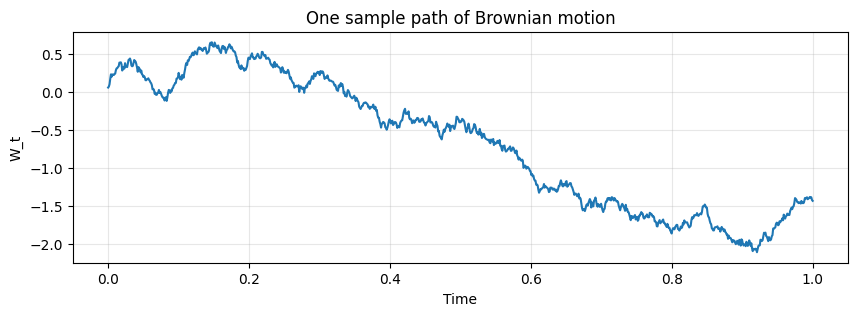

In [5]:
np.random.seed(0)
T_steps = 1000
dt = 1 / T_steps
dW = np.random.normal(0, np.sqrt(dt), T_steps)
W = np.cumsum(dW)
t = np.linspace(0, 1, T_steps)

plt.figure(figsize=(10, 3))
plt.plot(t, W)
plt.xlabel('Time')
plt.ylabel('W_t')
plt.title('One sample path of Brownian motion')
plt.grid(True, alpha=0.3)
plt.show()


## 5. Geometric Brownian Motion (GBM)

### The model

We model the stock price $S_t$ as:
$$
dS_t = \mu S_t\, dt + \sigma S_t\, dW_t.
$$

Read each term:
| Symbol | Name | Plain English |
|---|---|---|
| $S_t$ | Stock price at time $t$ | What we observe in the market |
| $\mu$ | Drift | Average rate of return (under the real-world measure) |
| $\sigma$ | Volatility | How much randomness there is; larger $\sigma$ = wilder swings |
| $dW_t$ | Brownian increment | The random shock at time $t$ |
| $dt$ | Small time step | "Over the next instant..." |

**Why multiply by $S_t$?** So that the stock price stays positive (you cannot have negative prices), and so that **percentage returns** are what look normal — which matches what we see in data.

### The closed-form solution

Integrating the SDE (we skip the Itô calculus details here) gives:
$$
S_T = S_0 \exp\!\left[\left(\mu - \tfrac12\sigma^2\right)T + \sigma\sqrt{T}\,Z\right],
\qquad Z \sim \mathcal N(0,1).
$$

**What each part means:**
- $\mu T$ = expected log-return over $[0,T]$
- $-\tfrac12\sigma^2 T$ = the **Jensen correction**. Because we exponentiate a normal random variable, the average of $S_T$ is *not* $S_0 e^{\mu T}$ — it is $S_0 e^{\mu T}$ only if we use the corrected drift. Without the $-\tfrac12\sigma^2$, the math would not be consistent.
- $\sigma\sqrt{T}\,Z$ = the random part; standard deviation of log-return is $\sigma\sqrt{T}$

So $\log(S_T/S_0)$ is normal with mean $(\mu - \tfrac12\sigma^2)T$ and variance $\sigma^2 T$. We say $S_T$ is **lognormal**.


In [6]:
S0, mu, sigma, T = 100, 0.08, 0.20, 1.0
Z = np.random.normal(size=10000)
S_T = S0 * np.exp((mu - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
print(f"Mean of S_T:     {S_T.mean():.2f}  (theory: S0*exp(mu*T) = {S0*np.exp(mu*T):.2f})")
print(f"Std of log-return: {np.log(S_T/S0).std():.4f}  (theory: sigma*sqrt(T) = {sigma*np.sqrt(T):.4f})")


Mean of S_T:     108.10  (theory: S0*exp(mu*T) = 108.33)
Std of log-return: 0.1978  (theory: sigma*sqrt(T) = 0.2000)


## 6. Switching to the risk-neutral world

In Section 3, we saw that pricing uses risk-neutral probabilities where the stock grows at rate $r$. In continuous time, the same idea applies:

**Under the risk-neutral measure $\mathbb Q$, the stock follows:**
$$
dS_t = r S_t\, dt + \sigma S_t\, dW_t^{\mathbb Q}.
$$

The only change from the real-world SDE is: **replace $\mu$ by $r$**. The volatility $\sigma$ stays the same.

**Why?** Risk-neutral pricing requires that the discounted stock price $e^{-rt}S_t$ be a martingale — its expected future value equals its current value (after discounting). That condition forces the drift to be $r$ under $\mathbb Q$.

**Practical consequence:** When we compute $C_0 = e^{-rT} E^{\mathbb Q}[(S_T - K)^+]$, we use the lognormal distribution of $S_T$ with drift $r - \tfrac12\sigma^2$ (not $\mu - \tfrac12\sigma^2$).


---

# Part II — Black-Scholes formula from first principles

## 7. The pricing formula

Apply the risk-neutral pricing formula from Section 3 to a call:
$$
C_0 = e^{-rT}\,E^{\mathbb Q}\bigl[(S_T - K)^+\bigr].
$$

Under $\mathbb Q$, $S_T = S_0 \exp\bigl[(r - \tfrac12\sigma^2)T + \sigma\sqrt{T}\,Z\bigr]$ with $Z \sim \mathcal N(0,1)$.

Define $X = (r - \tfrac12\sigma^2)T + \sigma\sqrt{T}\,Z$, so $\log(S_T/S_0) = X$ and $S_T = S_0 e^X$.

The call pays off only when $S_T > K$, i.e. when $X > \log(K/S_0)$.

### Step-by-step computation

Write the expectation as an integral against the density of $Z$:
$$
C_0 = e^{-rT}\int_{-\infty}^{\infty} \max(S_0 e^{\sigma\sqrt{T}z + (r-\sigma^2/2)T} - K,\, 0)\,\frac{e^{-z^2/2}}{\sqrt{2\pi}}\,dz.
$$

The max is positive when $z > d_2$, where
$$
d_2 = \frac{\log(S_0/K) + (r - \sigma^2/2)T}{\sigma\sqrt{T}}.
$$

Split the integral and evaluate (standard Gaussian integrals):
$$
C_0 = S_0\,N(d_1) - K e^{-rT}\,N(d_2),
$$
where
$$
d_1 = d_2 + \sigma\sqrt{T} = \frac{\log(S_0/K) + (r + \sigma^2/2)T}{\sigma\sqrt{T}}.
$$

Here $N(\cdot)$ is the standard normal cumulative distribution function: $N(x) = P(Z \le x)$ for $Z \sim \mathcal N(0,1)$.

**This is the Black-Scholes formula.** Every variable has a meaning — we explain $d_1$ and $d_2$ next.


## 8. What $d_1$ and $d_2$ actually mean

### $d_2$ — the standardized log-moneyness

$$
d_2 = \frac{\log(S_0/K) + (r - \sigma^2/2)T}{\sigma\sqrt{T}}.
$$

- $\log(S_0/K)$: how far the log-spot is above the log-strike. Positive = call is in the money.
- $(r - \sigma^2/2)T$: expected log-return under $\mathbb Q$
- $\sigma\sqrt{T}$: standard deviation of log-return

So $d_2$ answers: **"How many standard deviations is the log-forward above the log-strike?"**

And crucially:
$$
\boxed{N(d_2) = \mathbb Q(S_T > K) = \text{risk-neutral probability the call finishes in the money}.}
$$

### $d_1$ — related, but not quite the same probability

$$
d_1 = d_2 + \sigma\sqrt{T}.
$$

It turns out $N(d_1)$ is not a probability under $\mathbb Q$, but under a related measure. The practical fact you need for the exam:

$$
\boxed{\Delta = \frac{\partial C}{\partial S_0} = N(d_1).}
$$

So $N(d_1)$ tells you **how many shares of stock the call "acts like"** locally.

### Reading the formula in plain English

$$
C_0 = \underbrace{S_0\,N(d_1)}_{\text{expected stock receipt}} - \underbrace{K e^{-rT}\,N(d_2)}_{\text{expected strike payment}}.
$$

You receive stock (weighted by $N(d_1)$) and pay the strike (weighted by $N(d_2)$ and discounted).


In [7]:
def bs_call(S, K, T, r, sigma):
    std = sigma * np.sqrt(T)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / std
    d2 = d1 - std
    return S * norm.cdf(d1) - K * np.exp(-r*T) * norm.cdf(d2), d1, d2

S0, K, T, r, sigma = 100, 100, 1, 0.05, 0.20
C, d1, d2 = bs_call(S0, K, T, r, sigma)
print(f"Call price: {C:.4f}")
print(f"d1 = {d1:.4f},  N(d1) = {norm.cdf(d1):.4f}  (= delta)")
print(f"d2 = {d2:.4f},  N(d2) = {norm.cdf(d2):.4f}  (= risk-neutral prob ITM)")


Call price: 10.4506
d1 = 0.3500,  N(d1) = 0.6368  (= delta)
d2 = 0.1500,  N(d2) = 0.5596  (= risk-neutral prob ITM)


## 9. The Greeks — definitions in plain English

The **Greeks** are partial derivatives of the option price. They tell you how sensitive the price is to changes in inputs.

| Greek | Formula | Plain English |
|---|---|---|
| **Delta** ($\Delta$) | $\dfrac{\partial C}{\partial S} = N(d_1)$ | If the stock moves up \$1, the call price moves up about $\Delta$ dollars. Also: number of shares to hold in a delta hedge. |
| **Gamma** ($\Gamma$) | $\dfrac{\partial^2 C}{\partial S^2} = \dfrac{N'(d_1)}{S\sigma\sqrt{T}}$ | How fast delta changes when the stock moves. High gamma = delta changes quickly = hedge needs frequent rebalancing. |
| **Vega** ($\nu$) | $\dfrac{\partial C}{\partial \sigma} = S\sqrt{T}\,N'(d_1)$ | If volatility goes up 1 percentage point (0.01), the call price goes up about $\nu \times 0.01$ dollars. Always positive for a call. |

Here $N'(x) = \dfrac{1}{\sqrt{2\pi}} e^{-x^2/2}$ is the standard normal **density** (the bell curve).

**Why gamma matters for hedging:** Delta hedging removes first-order risk. But when the stock moves, delta changes (because of gamma). So you must buy or sell stock to rebalance. That rebalancing cost is driven by gamma. Topic A develops this into the "dollar gamma rebalancing" formula.


In [8]:
def bs_greeks(S, K, T, r, sigma):
    std = sigma * np.sqrt(T)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / std
    d2 = d1 - std
    delta = norm.cdf(d1)
    gamma = norm.pdf(d1) / (S * std)
    vega = S * np.sqrt(T) * norm.pdf(d1)
    return delta, gamma, vega

delta, gamma, vega = bs_greeks(S0, K, T, r, sigma)
print(f"Delta: {delta:.4f}")
print(f"Gamma: {gamma:.4f}")
print(f"Vega:  {vega:.4f}")


Delta: 0.6368
Gamma: 0.0188
Vega:  37.5240


## 10. Why hedging matters — the delta hedge in plain language

Suppose you **sold** a call option to a client. At expiry you owe them $(S_T - K)^+$ — a random amount depending on where the stock ends up.

**The problem:** You do not know $S_T$ today. You have **risk**.

**The delta hedge:** Hold $\Delta$ shares of stock. If the stock moves up a tiny amount, the gain on your stock position approximately cancels the loss on your short call (and vice versa). You are **locally hedged**.

**The analogy:** Riding a bicycle. Delta is how much you are leaning. Gamma is how quickly the required lean changes as the bike moves. You must constantly adjust (rebalance) to stay upright. That adjustment has a cost — that cost is related to gamma and realized volatility.

**Dollar delta** = $S \Delta$ = dollar value of shares in the hedge.
**Dollar gamma** = $S^2 \Gamma$ = sensitivity of dollar delta to a 1% move in the stock (developed fully in Topic A).


---

# Part III — Building blocks used everywhere

## 11. Forward prices

### What is a forward contract?

A **forward** is an agreement made today to buy (or sell) the stock at time $T$ at a fixed **delivery price** $K_{\mathrm{fwd}}$. Both parties are obligated — there is no optionality.

At expiry, the payoff is $S_T - K_{\mathrm{fwd}}$ (positive if the stock rose, negative if it fell).

### What is the fair forward price?

The **time-0 forward price** $F_0$ is the delivery price that makes the forward contract worth **zero** today.

**Replication argument (no dividends):**
1. Borrow $S_0$ today, buy one share.
2. At time $T$: you hold one share worth $S_T$, and you owe $S_0 e^{rT}$.
3. This portfolio replicates the payoff $S_T - S_0 e^{rT}$ at time $T$.

So the forward with delivery price $K_{\mathrm{fwd}} = S_0 e^{rT}$ has zero value today. Therefore:
$$
\boxed{F_0 = S_0 e^{rT}.}
$$

**With continuous dividend yield $q$:** the stock pays dividends that reduce the forward:
$$
F_0 = S_0 e^{(r-q)T}.
$$

**Plain English:** The forward price is what you would expect the stock to be worth at time $T$ if it grew at the risk-free rate (minus dividends).


In [9]:
S0, r, T = 100, 0.05, 1.0
F0 = S0 * np.exp(r * T)
print(f"Forward price F0 = S0 * exp(rT) = {F0:.4f}")


Forward price F0 = S0 * exp(rT) = 105.1271


## 12. Put-call parity

### The idea

Consider two portfolios at expiry:

**Portfolio A:** long call + $K e^{-rT}$ in the bank (enough to pay strike $K$ at time $T$)

**Portfolio B:** long put + one share of stock

**Payoff in each state:**
| $S_T$ | Portfolio A | Portfolio B |
|---|---|---|
| $S_T > K$ | $(S_T - K) + K = S_T$ | $0 + S_T = S_T$ |
| $S_T \le K$ | $0 + K = K$ | $(K - S_T) + S_T = K$ |

Both pay $\max(S_T, K)$. By no-arbitrage, they must have the same price today:
$$
C_0 + K e^{-rT} = P_0 + S_0.
$$

Rearranging:
$$
\boxed{C_0 - P_0 = S_0 - K e^{-rT} = e^{-rT}(F_0 - K).}
$$

**Uses:**
- Given call price and strike, infer put price (or vice versa)
- Given call and put at same strike, infer forward price: $F_0 = K + e^{rT}(C_0 - P_0)$
- This is exactly what Practice-Midterm Problem 1 part (a) tests


In [10]:
C0 = bs_call(S0, K, T, r, 0.20)[0]
P0 = C0 - S0 + K * np.exp(-r*T)
print(f"Call price: {C0:.4f}")
print(f"Put price from parity: {P0:.4f}")
print(f"Direct BS put check: {S0*np.exp(-r*T)*norm.cdf(-(np.log(S0/K)+(r-0.5*0.2**2)*T)/(0.2*np.sqrt(T))) - K*np.exp(-r*T)*norm.cdf(-(np.log(S0/K)+(r-0.5*0.2**2)*T)/(0.2*np.sqrt(T)) + 0.2*np.sqrt(T)):.4f}")


Call price: 10.4506
Put price from parity: 5.5735
Direct BS put check: -7.5676


## 13. Conditional expectation and the tower property

This section explains an identity that looks like "magic" but is just a law of averages.

### A concrete example first (two dice)

Roll two fair dice. Let $X$ = value of the first die, $Y$ = sum of both dice.

**Direct calculation:** $E[Y] = 7$ (the average of 2 through 12).

**Via conditioning on $X$:** If the first die shows $x$, the second die is uniform on $\{1,\ldots,6\}$, so
$$
E[Y \mid X = x] = x + 3.5.
$$
Now average over $x = 1,\ldots,6$:
$$
E[E[Y \mid X]] = \frac{1}{6}\sum_{x=1}^6 (x + 3.5) = 3.5 + 3.5 = 7.
$$

Same answer. **The tower property says this always works:**
$$
\boxed{E[Y] = E[E[Y \mid X]].}
$$

**Plain English:** To find the overall average of $Y$, you can first find the average of $Y$ in each "scenario" defined by $X$, then average those scenario-averages.

### Why this matters for option pricing

Suppose the payoff depends on two random quantities — say $S_{T_1}$ (stock at an intermediate date) and $S_{T_2}$ (stock at expiry).

Write $Y$ = discounted payoff at time 0.

Then:
$$
C_0 = E^{\mathbb Q}[Y] = E^{\mathbb Q}\bigl[E^{\mathbb Q}[Y \mid S_{T_1}]\bigr].
$$

**The inner expectation** $E^{\mathbb Q}[Y \mid S_{T_1}]$ is the price at time $T_1$ **given that we already know** $S_{T_1}$. Often this inner price has a closed-form formula (e.g. Black-Scholes with a shifted strike).

**The outer expectation** averages over all possible values of $S_{T_1}$.

This is called **conditional Monte Carlo** (Topic F). It reduces variance because we eliminate the randomness from the first time period analytically.

**Example preview (Practice-Final P3):** An Asian-style call pays on the average of $S_{0.5}$ and $S_{1.0}$. Condition on $S_{0.5}$; given $S_{0.5}$, the remaining payoff is a call-like function of $S_{1.0}$, which has a BS price. Average those BS prices over simulated $S_{0.5}$ values.


In [11]:
# Tower property with dice
E_Y_direct = 7.0
E_Y_tower = sum((x + 3.5) for x in range(1, 7)) / 6
print(f"E[Y] direct:           {E_Y_direct}")
print(f"E[E[Y|X]] via tower:   {E_Y_tower}")
print(f"Match: {E_Y_direct == E_Y_tower}")


E[Y] direct:           7.0
E[E[Y|X]] via tower:   7.0
Match: True


---

# Part IV — Worked application: Practice-Midterm Problem 1

This problem tests everything in Part III: put-call parity, forward prices, and extracting probabilities from option prices.

### The data

European options on RUT (Russell 2000 index), expiry $T = 25/365$ years, interest rate $r = 0.0432$.

| Strike | Call price | Put price |
|---|---|---|
| 2280 | 44.7 | 59.2 |
| 2290 | 39.9 | ? |
| 2300 | 35.4 | ? |

---

### Part (a) — Find the forward price $F_0$

**What is being asked?** The fair price to deliver the index at time $T$.

**Formula (from Section 12):** $F_0 = K + e^{rT}(C_0 - P_0)$ at any strike $K$.

**Plug in** at $K = 2280$:
$$
F_0 = 2280 + e^{0.0432 \cdot 25/365}(44.7 - 59.2) = 2280 - 14.5\,e^{0.00296}.
$$

Numerically: $F_0 \approx 2265.46$.

**Interpretation:** The market implies the index forward is about 2265, below the 2280 strike — the options are mostly out of the money on the call side at that strike.

---

### Part (b) — Value of a forward with delivery price 2200

**What is being asked?** How much is a forward contract worth today if you agreed to buy at 2200?

**Formula:** A forward with delivery price $K$ has time-0 value $e^{-rT}(F_0 - K)$.

$$
\text{Value} = e^{-rT}(2265.46 - 2200) \approx 65.26.
$$

**Interpretation:** Positive — the forward delivery price 2200 is below the fair forward 2265, so the contract is valuable to the long side.

---

### Part (c) — Probability that $2287 < S_T < 2293$

**What is being asked?** Approximate the risk-neutral probability that the index finishes in a small window.

**Tool: Breeden-Litzenberger.** The risk-neutral **density** of $S_T$ at strike $K$ is:
$$
f(K) = e^{rT}\,\frac{\partial^2 C}{\partial K^2}.
$$

Approximate the second derivative with a **butterfly** (finite difference across three strikes):
$$
f(K) \approx e^{rT}\,\frac{C(K-\Delta K) - 2C(K) + C(K+\Delta K)}{(\Delta K)^2}.
$$

At $K = 2290$ with $\Delta K = 10$:
$$
f(2290) \approx e^{rT}\,\frac{44.7 - 2(39.9) + 35.4}{100} = e^{rT}\,\frac{0.3}{100} \approx 0.00301.
$$

The window $2287$ to $2293$ has width 6, so:
$$
\mathbb Q(2287 < S_T < 2293) \approx f(2290) \times 6 \approx 0.018.
$$

**Interpretation:** About 1.8% risk-neutral probability — a small window far from the forward.

---

### Part (d) — Probability that $S_T > 2290$

**What is being asked?** Tail probability above 2290.

**Tool:** Differentiate the call price once in strike:
$$
\frac{\partial C}{\partial K} = -e^{-rT}\,\mathbb Q(S_T > K).
$$

So:
$$
\mathbb Q(S_T > K) \approx -e^{rT}\,\frac{C(K+\Delta K) - C(K-\Delta K)}{2\Delta K}.
$$

At $K = 2290$:
$$
\mathbb Q(S_T > 2290) \approx -e^{rT}\,\frac{35.4 - 44.7}{20} = e^{rT}\,\frac{9.3}{20} \approx 0.466.
$$

**Interpretation:** About 46.6% chance (under $\mathbb Q$) that RUT finishes above 2290.

---

### Part (e) — Fill in the missing put price at strike 2300

**What is being asked?** Use put-call parity to back out $P_0(2300)$.

**Formula:** $P_0 = C_0 - e^{-rT}(F_0 - K)$.

$$
P_0(2300) = 35.4 - e^{-rT}(2265.46 - 2300) = 35.4 + e^{-rT}(34.54) \approx 69.84.
$$


In [12]:
r = 0.0432
T = 25 / 365
disc = np.exp(-r * T)
grow = np.exp(r * T)

C2280, P2280 = 44.7, 59.2
C2290 = 39.9
C2300 = 35.4

F0 = 2280 + grow * (C2280 - P2280)
print(f"(a) F_0 = {F0:.4f}")

forward_2200 = disc * (F0 - 2200)
print(f"(b) Forward value (delivery 2200) = {forward_2200:.4f}")

density_2290 = grow * (C2280 - 2*C2290 + C2300) / 100
P_window = density_2290 * 6
print(f"(c) P(2287 < S_T < 2293) ≈ {P_window:.4f}")

P_above = -grow * (C2300 - C2280) / 20
print(f"(d) P(S_T > 2290) ≈ {P_above:.4f}")

P2300 = C2300 - disc * (F0 - 2300)
print(f"(e) P(2300) via parity = {P2300:.4f}")


(a) F_0 = 2265.4570
(b) Forward value (delivery 2200) = 65.2636
(c) P(2287 < S_T < 2293) ≈ 0.0181
(d) P(S_T > 2290) ≈ 0.4664
(e) P(2300) via parity = 69.8409


---

## Cheat sheet — Topic 0

| # | Formula | When to use |
|---|---|---|
| 1 | Price $= e^{-rT} E^{\mathbb Q}[Y]$ | Every pricing problem |
| 2 | $C_0 = S_0 N(d_1) - K e^{-rT} N(d_2)$ | European call (no div) |
| 3 | $d_{1,2} = \dfrac{\log(S_0/K) + (r \pm \sigma^2/2)T}{\sigma\sqrt{T}}$ | Compute $N(d_1)$, $N(d_2)$ |
| 4 | $\Delta = N(d_1)$, $\Gamma = N'(d_1)/(S\sigma\sqrt{T})$, vega $= S\sqrt{T}\,N'(d_1)$ | Greeks |
| 5 | $F_0 = S_0 e^{rT}$ (no div) | Forward price |
| 6 | $C - P = e^{-rT}(F_0 - K)$ | Put-call parity; infer $F_0$ |
| 7 | $E[Y] = E[E[Y \mid X]]$ | Conditional Monte Carlo |
| 8 | $f(K) = e^{rT} \partial^2 C / \partial K^2$ | Risk-neutral density from options |
| 9 | $\mathbb Q(S_T > K) \approx -e^{rT}\,\dfrac{\partial C}{\partial K}$ | Tail probability from call prices |

---

*Next:* **Topic A — L1: Analytic Approximations & Implied Volatility** (Practice-Final Problem 1).
